---
tags: [tutorial]
---

# Execution Workflow

This notebook uses a small VQE (Variational Quantum Eigensolver) example to walk through the workflow of converting a qkernel to a supported quantum SDK/IR and executing it on the target. We use Qiskit as the target below.

Given a target Hamiltonian $H$, VQE repeatedly executes a parameterized quantum circuit $\ket{\psi(\theta)}$ and updates its parameters using the execution results. The algorithm seeks to lower the Hamiltonian's energy (expectation value) $\bra{\psi(\theta)}H\ket{\psi(\theta)}$ by finding suitable parameters $\theta$. See [Peruzzo et al. (2014)](https://doi.org/10.1038/ncomms5213).

This notebook focuses on how to use qkernels to compute expectation values and measure bit strings, without going into parameter optimization methods.

In [1]:
# Install Qamomile and the packages used in this notebook.
# !pip install "qamomile[qiskit,visualization]" scipy

In [2]:
import math

import matplotlib.pyplot as plt
from qiskit_aer import AerSimulator
from scipy.optimize import minimize

import qamomile.circuit as qmc
import qamomile.observable as qmo
from qamomile.qiskit import QiskitTranspiler

## 1. Prepare the Transpiler and Executor

We use a Transpiler to transpile a qkernel and an Executor to execute it. Since we use Qiskit in this example, we prepare `QiskitTranspiler` and `QiskitExecutor`. The basic procedure is the same when specifying other targets. Here, we explicitly provide AerSimulator as the Executor's backend for reproducibility, but the `executor` function of `QiskitTranspiler` automatically uses `AerSimulator` as the backend when called without arguments.

In [3]:
transpiler = QiskitTranspiler()
executor = transpiler.executor(backend=AerSimulator(seed_simulator=42))

## 2. Define a Parameterized qkernel

First, we define a parameterized qkernel. We prepare an $n$-qubit state and apply $R_Y(\theta_i)$ to each qubit:

$$
\ket{\psi_n(\theta)}
= \bigotimes_{i} R_Y(\theta_i)\ket{0}
= \bigotimes_{i}\left( \cos\frac{\theta_i}{2}\ket{0} +\sin\frac{\theta_i}{2}\ket{1} \right)
$$

Similarly, we define a qkernel that measures this quantum state. We use the `measure()` function to perform the measurement.

In [4]:
@qmc.qkernel
def parameterized_state(
    n: qmc.UInt, thetas: qmc.Vector[qmc.Float]
) -> qmc.Vector[qmc.Qubit]:
    """Prepare n qubits with a separate rotation angle for each qubit without measuring them."""
    q = qmc.qubit_array(n, "q")
    for i in qmc.range(n):
        q[i] = qmc.ry(q[i], thetas[i])
    return q


@qmc.qkernel
def sample_state(n: qmc.UInt, thetas: qmc.Vector[qmc.Float]) -> qmc.Vector[qmc.Bit]:
    """Measure every qubit of the variational state in the computational basis."""
    q = parameterized_state(n=n, thetas=thetas)
    return qmc.measure(q)

We transpile the `sample_state` qkernel into an object that can be executed with Qiskit. Note that only qkernels with classical inputs (or no inputs) and classical outputs can be transpiled.

For simplicity, we set $n = 1$:

$$
\ket{\psi_1} = \cos\frac{\theta}{2}\ket{0} +\sin\frac{\theta}{2}\ket{1}
$$

For execution, we specify the parameters that determine the circuit structure, in this case the number of qubits `n`, through `bindings` at transpilation time. We specify `thetas`, whose values will be updated through circuit execution, in `parameters` so that they remain parameters.

In [5]:
sample_executable = transpiler.transpile(
    sample_state,
    bindings={"n": 1},
    parameters=["thetas"],
)

qiskit_circuit = sample_executable.get_first_circuit()
print(f"Qubits: {qiskit_circuit.num_qubits}")
print(f"Runtime parameters: {sample_executable.parameter_names}")
qiskit_circuit.draw()

Qubits: 1
Runtime parameters: ['thetas[0]']


┌───────────────┐┌─┐
  q: ┤ Ry(thetas[0]) ├┤M├
     └───────────────┘└╥┘
c: 1/══════════════════╩═
                       0

Now we execute the transpiled Qiskit quantum circuit. We use the `sample()` function to measure a bit string from the qubits. Since we left `thetas` as a parameter, we need to specify it at execution time. We provide `bindings` at execution time in the same way as when fixing parameter values at transpilation time. Here, we execute the circuit with an initial angle of $\pi / 2$.

The `sample()` function returns a job. The user retrieves the result from this job using the `result()` function. This design supports the asynchronous execution flow used when running on real hardware.

In [6]:
shots = 1024
initial_thetas = [math.pi / 2]

initial_bindings = {"thetas": initial_thetas}
sample_job = sample_executable.sample(
    executor,
    shots=shots,
    bindings=initial_bindings,
)

print(type(sample_job))

<class 'qamomile.circuit.transpiler.job.SampleJob'>


In [7]:
initial_sample = sample_job.result()

print("Initial counts:", initial_sample.results)
print("Initial probabilities:", initial_sample.probabilities())
assert sum(count for _, count in initial_sample.results) == shots

Initial counts: [((0,), 526), ((1,), 498)]
Initial probabilities: [((0,), 0.513671875), ((1,), 0.486328125)]


The results obtained from `sample()` have a `results` attribute that stores the results in the format `[(value, count), ...]`. The `probabilities()` function lets us compute empirical probabilities from these sample results.

## 3. Evaluate the Energy with `expval()` and `run()`

Next, we update the parameters of the quantum state we defined to lower the expectation value of a given Hamiltonian. Within the qkernel, we use `expval()` instead of `measure()` to compute the expectation value. `expval()` takes an `Observable` argument. This is the Hamiltonian whose expectation value we compute. We therefore define a qkernel for computing expectation values separately from the earlier `sample_state`.

In [8]:
@qmc.qkernel
def run_state(
    n: qmc.UInt,
    thetas: qmc.Vector[qmc.Float],
    observable: qmc.Observable,
) -> qmc.Float:
    """Evaluate an observable on the shared variational state."""
    q = parameterized_state(n, thetas)
    return qmc.expval(q, observable)

We transpile this qkernel. Since `expval()` returns a floating-point value (a classical value), the qkernel can be transpiled. We also fix the Hamiltonian at transpilation time. In Qamomile, we construct a Hamiltonian as a Pauli sum using the Pauli operators in the `qamomile.observable` module. As with the `sample_state` qkernel, we specify `bindings` and `parameters` when transpiling.

In [9]:
hamiltonian = -qmo.Z(0) - qmo.X(0)

energy_executable = transpiler.transpile(
    run_state,
    bindings={"n": 1, "observable": hamiltonian},
    parameters=["thetas"],
)
print(f"Hamiltonian: {hamiltonian}")
print(f"Runtime parameters: {energy_executable.parameter_names}")

Hamiltonian: Hamiltonian((Z0,): -1.0, (X0,): -1.0)
Runtime parameters: ['thetas[0]']


While `sample()` is the function for measuring bit strings, `run()` is the function for computing expectation values. We can execute it with the same calling pattern as the `sample()` function.

In [10]:
energy_job = energy_executable.run(
    executor,
    bindings=initial_bindings,
)

print(type(energy_job))

<class 'qamomile.circuit.transpiler.job.ExpvalJob'>


In [11]:
initial_energy = energy_job.result()

print(f"Initial energy: {initial_energy:+.6f}")

Initial energy: -1.000000


## 4. Update Parameters Using the Transpiled Object

Here, we repeatedly execute the transpiled `run_state` qkernel while updating the parameters to lower the expectation value. For every execution, we update the parameters of the transpiled object, so there is no need to transpile the circuit multiple times. We use SciPy's `minimize` function to update the parameters.

In [12]:
history = []


def energy(theta_values):
    """Bind one trial angle and return the energy to the optimizer."""
    value = energy_executable.run(
        executor,
        bindings={"thetas": theta_values},
    ).result()
    history.append((theta_values, value))
    return value


optimized = minimize(
    energy,
    x0=initial_thetas,
    method="COBYLA",
    options={"maxiter": 50, "rhobeg": 0.5, "tol": 1e-6},
)
optimized_bindings = {"thetas": optimized.x}

print(f"Optimized thetas: {optimized_bindings['thetas']}")
print(f"Energy: {initial_energy:+.6f} -> {optimized.fun:+.6f}")
print("Energy evaluations:", optimized.nfev)
print("Optimizer status:", optimized.message)
assert math.isclose(optimized.fun, -math.sqrt(2), abs_tol=1e-6)

Optimized thetas: [0.78539786]
Energy: -1.000000 -> -1.414214
Energy evaluations: 36
Optimizer status: Return from COBYLA because the trust region radius reaches its lower bound.


For this circuit, $\langle Z\rangle=\cos\theta$ and $\langle X\rangle=\sin\theta$, so we obtain analytically

$$
\bra{\psi_1(\theta)} H \ket{\psi_1(\theta)}
=-\cos\theta-\sin\theta,\qquad \theta_\star=\pi/4\pmod{2\pi},\qquad E_\star=-\sqrt2
$$

This confirms that `minimize` has found the optimal parameter.

## 5. Compare the Optimization Process and Results

Finally, we examine how the energy changes during optimization and compare the probability distribution using the optimized parameters with the distribution using the initial values. Since `sample_state` has already been transpiled, we can call `sample()` using the object we already have.

In [13]:
optimized_sample = sample_executable.sample(
    executor,
    shots=shots,
    bindings=optimized_bindings,
).result()
print("Optimized counts:", optimized_sample.results)
print("Optimized probabilities:", optimized_sample.probabilities())

Optimized counts: [((1,), 129), ((0,), 895)]
Optimized probabilities: [((1,), 0.1259765625), ((0,), 0.8740234375)]


Using the parameter $\theta_* = \pi / 4$ we obtained, we have analytically

$$
\ket{\psi_1(\pi / 4)} = \cos\frac{\pi}{8}\ket{0} +\sin\frac{\pi}{8}\ket{1}
$$

We can see that the samples appear to be correct.

We plot these below.

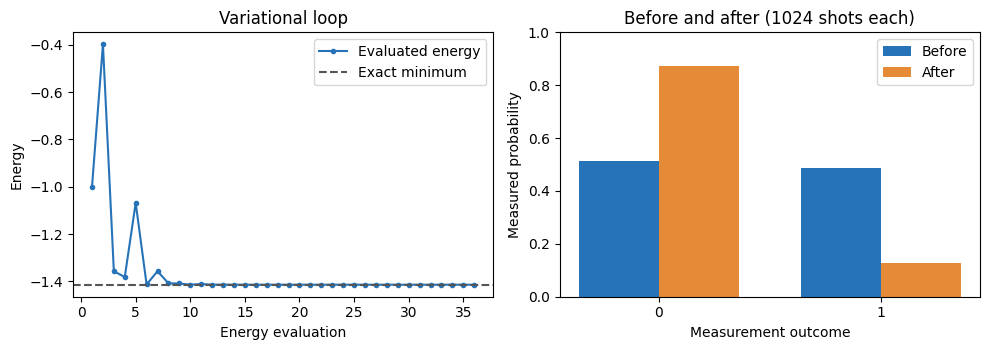

In [14]:
initial_probabilities = dict(initial_sample.probabilities())
optimized_probabilities = dict(optimized_sample.probabilities())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(
    range(1, len(history) + 1),
    [value for _, value in history],
    marker=".",
    color="#2673B8",
    label="Evaluated energy",
)
axes[0].axhline(-math.sqrt(2), color="#555555", linestyle="--", label="Exact minimum")
axes[0].set(xlabel="Energy evaluation", ylabel="Energy", title="Variational loop")
axes[0].legend()

axes[1].bar(
    [-0.18, 0.82],
    [initial_probabilities.get((bit,), 0.0) for bit in (0, 1)],
    width=0.36,
    label="Before",
    color="#2673B8",
)
axes[1].bar(
    [0.18, 1.18],
    [optimized_probabilities.get((bit,), 0.0) for bit in (0, 1)],
    width=0.36,
    label="After",
    color="#E58B38",
)
axes[1].set(
    xticks=[0, 1],
    xticklabels=["0", "1"],
    ylim=(0, 1),
    xlabel="Measurement outcome",
    ylabel="Measured probability",
    title=f"Before and after ({shots} shots each)",
)
axes[1].legend()
fig.tight_layout()
plt.show()

## Summary

In this notebook, we learned about transpilation and execution through a small VQE example. We saw how to use `bindings` and `parameters` to transpile while leaving the variables we want to update within the algorithm as parameters. We also saw how to use `expval()`/`run()` to compute expectation values and `measure()`/`sample()` to measure qubits.

Adapted from the [QCE 2026 tutorial](https://github.com/Jij-Inc/Qamomile-QCE2026-Tutorial/blob/main/docs/tutorials/en/03_execution_workflow.ipynb).